In [13]:
%env HF_HOME=/blue/uf-eig/FILLMEIN/cache/
%env TORCH_HOME=/blue/uf-eig/FILLMEIN/cache/ 

env: HF_HOME=/blue/uf-eig/FILLMEIN/cache/
env: TORCH_HOME=/blue/uf-eig/FILLMEIN/cache/


In [3]:
import numpy as np
import pandas as pd
import importlib
import matplotlib
import matplotlib.pyplot as plt
import platform
import sys
import os
import torch
import transformers
import tokenizers
import timm
import psutil
import random



from IPython.display import display
from transformers import AutoModelForVision2Seq, AutoProcessor
from PIL import Image
from pathlib import Path
from torchvision import transforms



/blue/uf-eig/FILLMEIN/.conda/envs/IForgotVLA/lib/python3.10/site-packages/wandb/sdk/internal/internal_api.py:30: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


### Load Libero Dataset

In [4]:
LIBERO_REPO = "./LIBERO" # YOU MIGHT NEED TO CHANGE THIS 

if LIBERO_REPO not in sys.path:
    sys.path.insert(0, LIBERO_REPO) # FIX: was not able to find libero and packages associated with it 

from libero.libero import benchmark
from libero.libero.envs import OffScreenRenderEnv
from libero.libero.utils import get_libero_path



# Since I moved my dataset had to use this
# from pathlib import Path
# import libero.libero as libero_pkg
# from libero.libero import get_libero_path

# print("LIBERO imported from:", libero_pkg.__file__)
# print("Configured BDDL root:", get_libero_path("bddl_files"))
# print("Requested BDDL file:", task_bddl_file)
# print("File exists:", Path(task_bddl_file).is_file())

# from pathlib import Path
# import libero.libero as libero_pkg
# from libero.libero import set_libero_default_path

# # Locate the current LIBERO installation
# libero_root = Path(libero_pkg.__file__).resolve().parent

# # Update ~/.libero/config.yaml
# set_libero_default_path(str(libero_root))

# print("Updated LIBERO path:", libero_root)

[robosuite WARNING] No private macro file found! (__init__.py:7)
[robosuite WARNING] It is recommended to use a private macro file (__init__.py:8)
[robosuite WARNING] To setup, run: python /blue/uf-eig/FILLMEIN/.conda/envs/IForgotVLA/lib/python3.10/site-packages/robosuite/scripts/setup_macros.py (__init__.py:9)
Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


In [5]:
benchmark_dict = benchmark.get_benchmark_dict() # 6 dicts for each tasks suite located above
# print(benchmark_dict)

task_suite_name = "libero_90"
task_suite = benchmark_dict[task_suite_name]() # The () instantiates the suite in memory

task_id = 5 # If you change this number you will get a different task name, & instructions
task = task_suite.get_task(task_id)

task_bddl_file = os.path.join(
    get_libero_path("bddl_files"),
    task.problem_folder,
    task.bddl_file
)

print("Task name:", task.name)
print("Instruction:", task.language)
print("BDDL file:", task_bddl_file)
print("BDDL exists:", os.path.exists(task_bddl_file))

Task name: KITCHEN_SCENE10_put_the_chocolate_pudding_in_the_top_drawer_of_the_cabinet_and_close_it
Instruction: put the chocolate pudding in the top drawer of the cabinet and close it
BDDL file: /blue/uf-eig/FILLMEIN/HSR-Replication/LIBERO/libero/libero/./bddl_files/libero_90/KITCHEN_SCENE10_put_the_chocolate_pudding_in_the_top_drawer_of_the_cabinet_and_close_it.bddl
BDDL exists: True


### Creating and Resetting the LIBERO Simulation Environment
This cell creates the LIBERO simulation environment for the selected task using `OffScreenRenderEnv`.

In [6]:
env = OffScreenRenderEnv(
    bddl_file_name=task_bddl_file,
    camera_heights=256,
    camera_widths=256,
)

env.seed(0)

obs = env.reset()

print("Reset success")
print("Obs keys:", obs.keys())

Reset success
Obs keys: odict_keys(['robot0_joint_pos', 'robot0_joint_pos_cos', 'robot0_joint_pos_sin', 'robot0_joint_vel', 'robot0_eef_pos', 'robot0_eef_quat', 'robot0_gripper_qpos', 'robot0_gripper_qvel', 'agentview_image', 'robot0_eye_in_hand_image', 'akita_black_bowl_1_pos', 'akita_black_bowl_1_quat', 'akita_black_bowl_1_to_robot0_eef_pos', 'akita_black_bowl_1_to_robot0_eef_quat', 'butter_1_pos', 'butter_1_quat', 'butter_1_to_robot0_eef_pos', 'butter_1_to_robot0_eef_quat', 'butter_2_pos', 'butter_2_quat', 'butter_2_to_robot0_eef_pos', 'butter_2_to_robot0_eef_quat', 'chocolate_pudding_1_pos', 'chocolate_pudding_1_quat', 'chocolate_pudding_1_to_robot0_eef_pos', 'chocolate_pudding_1_to_robot0_eef_quat', 'robot0_proprio-state', 'object-state'])


In [7]:
# Get one initial state from the benchmark
init_states = task_suite.get_task_init_states(task_id)
#print("num init states:", len(init_states))

obs = env.set_init_state(init_states[6])
# print(obs)
 
#print("obs keys:", obs.keys())


[Warning]: datasets path /blue/uf-eig/FILLMEIN/HSR-Replication/LIBERO/libero/libero/../datasets does not exist!


## Visualization and Basic Manual Testing

Now that the LIBERO environment can reset into a fixed task state, the next step is to visualize what the robot can observe.

This section shows the available camera views and adds small helper functions for manually moving the robot. The goal is to make the notebook easier to explore before connecting the environment to OpenVLA.

The two most important image observations are:

- `agentview_image`: third-person camera view of the table scene
- `robot0_eye_in_hand_image`: wrist camera view from the robot gripper

These views help verify that the scene is loaded correctly and that the robot has useful visual input for policy inference.

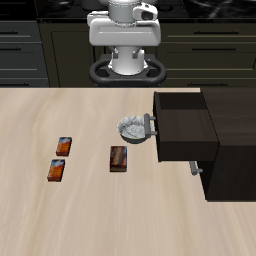

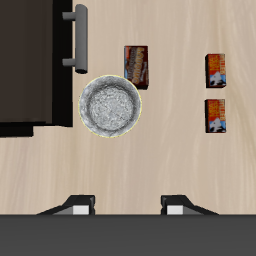

In [8]:
def show_robot_views(obs):
    image_key = []
    for i in obs:
        if "image" in i:
            #print(f"camera found: {i}")
            image_key.append(i)
    for key in image_key:
        img = obs[key]
        
        # Flipped vertically (upside down otherwise)
        display_img = img[::-1, ::-1]
        
        # display image is an array so use Image.fromarray
        display(Image.fromarray(display_img))
        
        
show_robot_views(obs)

### Simple Robot Movement Helpers

The next functions manually send small actions to the robot.

LIBERO actions are usually 7-dimensional:

```
actions = [x movement, y movement, z movement, roll, pitch, yaw, gripper] 
```

- Roll (Rotation around the X-axis): Tilts a robot from side to side (e.g., banking like an airplane).
- Pitch (Rotation around the Y-axis): Tilts a robot up and down, front to back (e.g., looking up or down).
- Yaw (Rotation around the Z-axis): Rotates the robot horizontally, turning it from side to side (e.g., spinning like a top).

For basic testing, we only modify the first three values for position and the last value for the gripper.

Small movement values are used because large actions can make the robot unstable or move too aggressively in simulation.
### How Step Count Works for Movement

The `steps` argument works the same way for robot movement as it does for the gripper.

Each movement command is applied repeatedly for a fixed number of simulation steps. A larger step count means the robot has more time to move in that direction.

For example:
`move_robot(dx=0.05, steps=10)`

means:

apply a small positive x-direction movement for 10 simulation steps

It does not teleport the robot to a new x-position. The robot moves gradually as the simulator updates.



### How Step Count Works for Gripper

The `steps` argument controls how long an action is repeatedly applied in the simulation.

Each time `env.step(action)` runs, the simulator advances forward by one control step. When we use `steps=10`, the same action is applied 10 times in a row.

For example:

`close_gripper(steps=10)`

does not mean “close the gripper by 10 units.” It means “send the close-gripper command for 10 simulation steps.”

A small step count applies the action briefly. A larger step count applies the action for longer.

- steps = 1    → very short command
- steps = 10   → short held command
- steps = 50   → longer held command

This matters because the robot and gripper do not move instantly. They change gradually as the simulator updates the physics and controller over multiple steps.




In [9]:
def move_robot(dx=0.0, dy=0.0, dz=0.0, steps=10):
    actions = np.zeros(7, dtype=np.float32)
    actions[0] = dx
    actions[1] = dy
    actions[2] = dz
    return sim_env(actions, steps=steps)
    
def open_gripper(steps):
    actions = np.zeros(7, dtype=np.float32)
    actions[-1] = -1.0
    return sim_env(actions, steps=steps)
    

def close_gripper(steps):
    actions = np.zeros(7, dtype=np.float32)
    actions[-1] = 1.0
    return sim_env(actions, steps=steps)
    
#-1 = open, +1 = close
def reset_to_fixed_state(index=0):
    env.reset() 
    obs = env.set_init_state(init_states[index])
    show_robot_views(obs)
    return obs

def wait_for_objects_to_settle(env, obs, num_steps=10):
    dummy_action = np.array([0, 0, 0, 0, 0, 0, -1], dtype=np.float32)

    for _ in range(num_steps):
        obs, reward, done, info = env.step(dummy_action)

    return obs

def print_robot_state(obs):
    print("End-effector position:", obs["robot0_eef_pos"])
    print("Gripper position:", obs["robot0_gripper_qpos"])

    
    
    
def show_before_after(before, after, title="Robot Action"):
    cameras = [
        "agentview_image",
        "robot0_eye_in_hand_image"
    ]




    fig, axes = plt.subplots(
        len(cameras), 2,
        figsize=(12, 4 * len(cameras)),
        squeeze=False
    )

    fig.suptitle(title, fontsize=16)

    for i, camera in enumerate(cameras):
        for j, (obs, label) in enumerate([
            (before, "BEFORE"),
            (after, "AFTER")
        ]):
            axes[i, j].imshow(obs[camera])
            axes[i, j].set_title(
                f"{label} — {camera}"
            )
            axes[i, j].axis("off")

    plt.tight_layout()
    plt.show()

def sim_env(action, steps=10, render=True):
    global obs

    cameras = ["agentview_image", "robot0_eye_in_hand_image"]

    # Save BEFORE images
    before = {cam: obs[cam].copy() for cam in cameras}

    # Execute action
    for _ in range(steps):
        obs, reward, done, info = env.step(action)
        if done:
            break

    # Display BEFORE vs AFTER
    if render:
        fig, axes = plt.subplots(2, 2, figsize=(12, 8))

        for i, cam in enumerate(cameras):
            axes[i, 0].imshow(np.flipud(before[cam]))
            axes[i, 0].set_title(f"BEFORE — {cam}")
            axes[i, 0].axis("off")

            axes[i, 1].imshow(np.flipud(obs[cam]))
            axes[i, 1].set_title(f"AFTER — {cam}")
            axes[i, 1].axis("off")

        plt.tight_layout()
        plt.show()

    print(f"Reward: {reward} | Done: {done}")

    return obs

### Use the code below to see manual movement

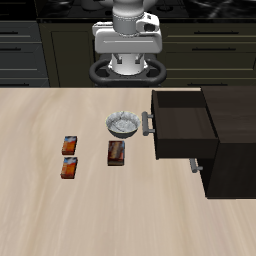

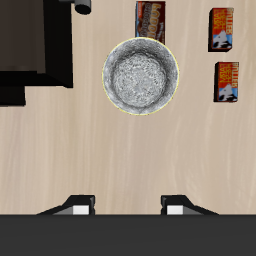

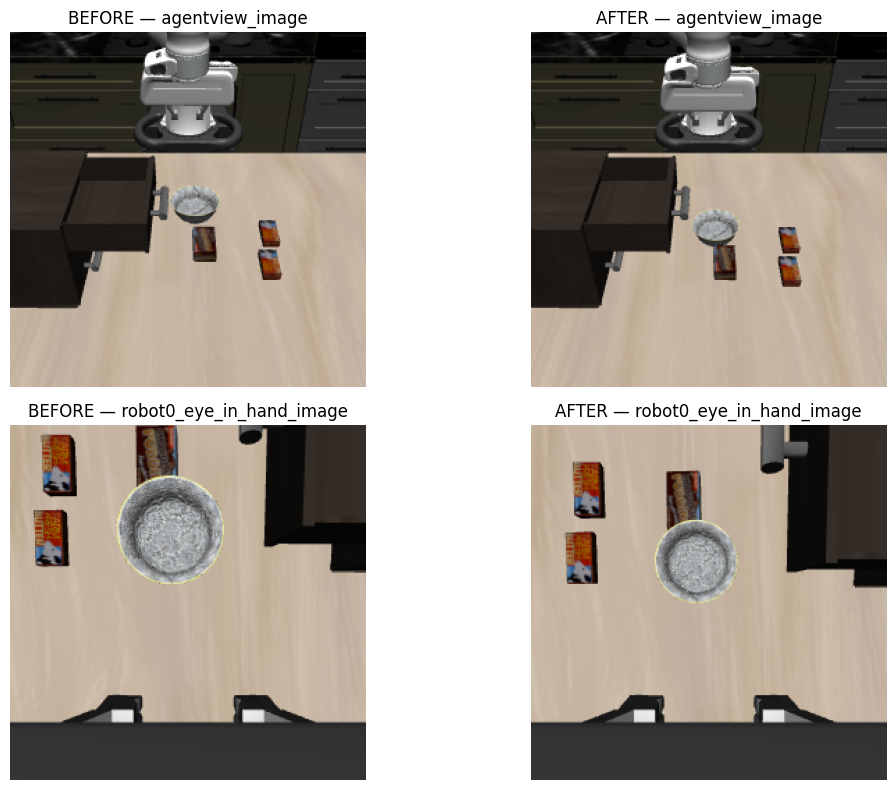

Reward: 0.0 | Done: False


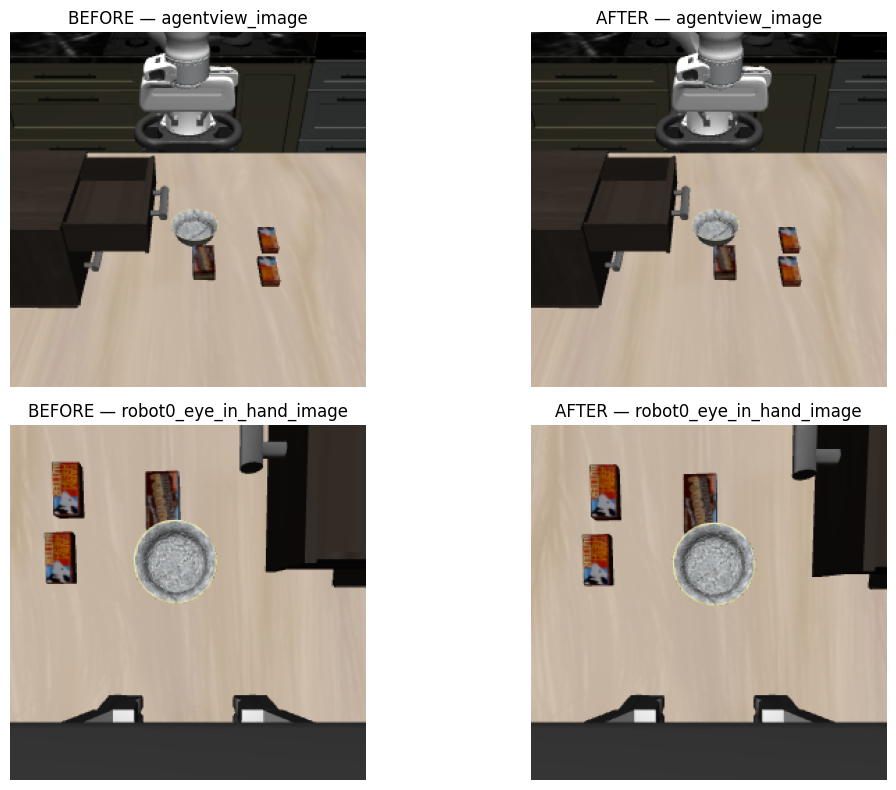

Reward: 0.0 | Done: False


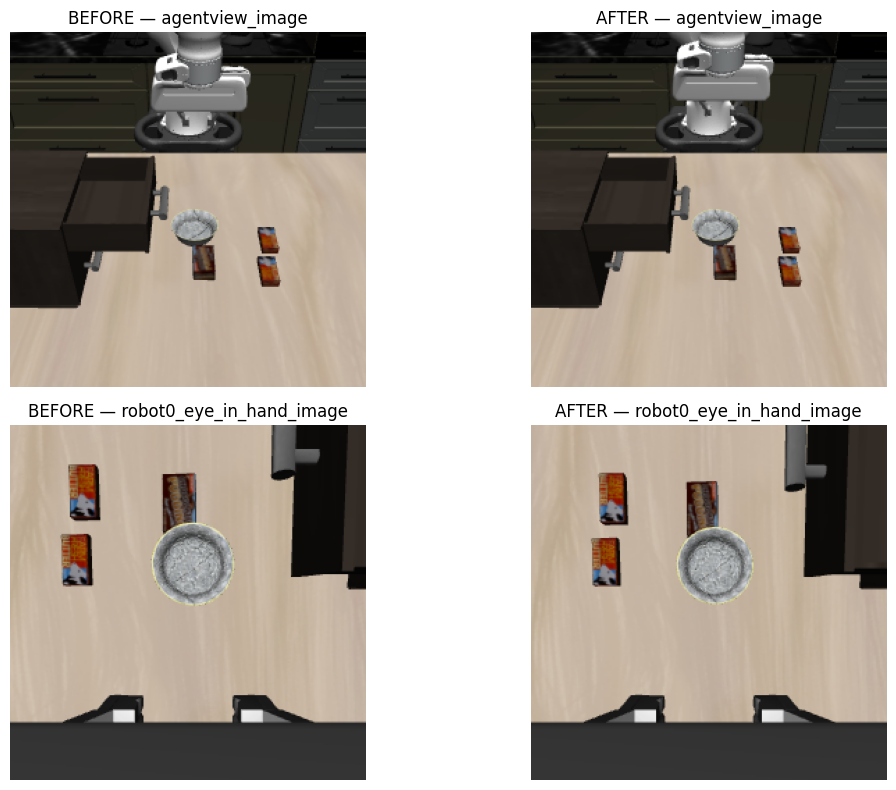

Reward: 0.0 | Done: False


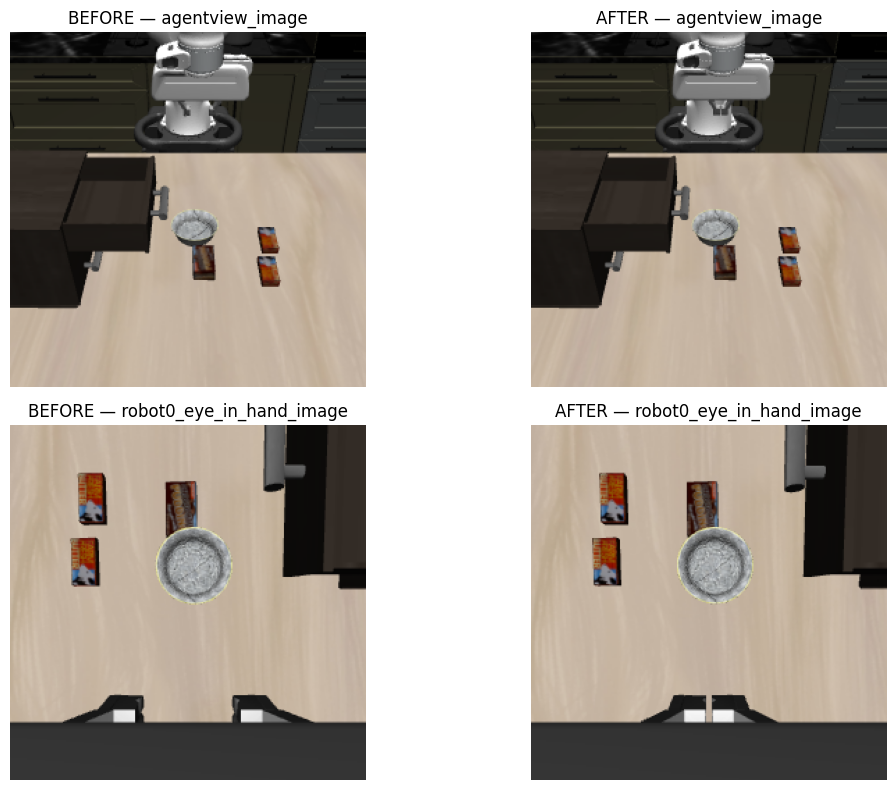

Reward: 0.0 | Done: False


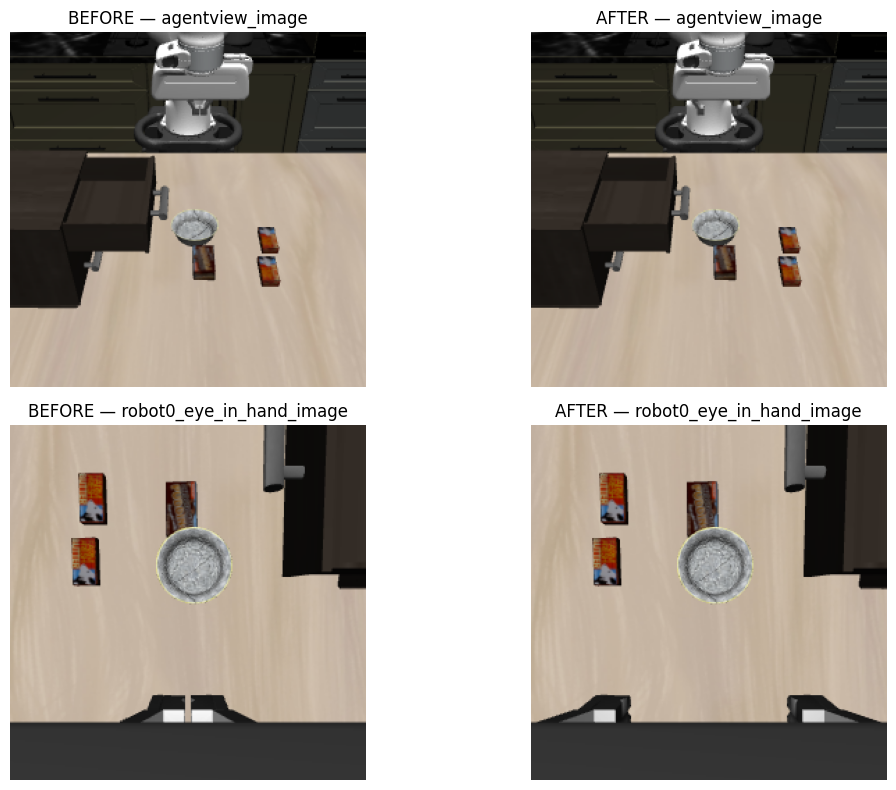

Reward: 0.0 | Done: False


In [12]:
# Reset environment
obs = reset_to_fixed_state()

# Move along X
obs = move_robot(dx=0.2, steps=10)

# Move along Y
obs = move_robot( dy=0.2, steps=10)

# Move along Z
obs = move_robot(dz=0.2, steps=10)

# Test gripper
obs = close_gripper(steps=10)
obs = open_gripper(steps=10)